In [1]:
%pip install datasets

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
from datasets import load_dataset

ds = load_dataset("nbertagnolli/counsel-chat")
df = ds["train"].to_pandas()
df.head()

Repo card metadata block was not found. Setting CardData to empty.


,questionID,questionTitle,questionText,questionLink,topic,therapistInfo,therapistURL,answerText,upvotes,views
0,0,Do I have too many issues for counseling?,I have so many issues to address. I have a his...,https://counselchat.com/questions/do-i-have-to...,depression,Jennifer MolinariHypnotherapist & Licensed Cou...,https://counselchat.com/therapists/jennifer-mo...,It is very common for people to have multiple ...,3,1971
1,0,Do I have too many issues for counseling?,I have so many issues to address. I have a his...,https://counselchat.com/questions/do-i-have-to...,depression,"Jason Lynch, MS, LMHC, LCAC, ADSIndividual & C...",https://counselchat.com/therapists/jason-lynch...,"I've never heard of someone having ""too many i...",2,386
2,0,Do I have too many issues for counseling?,I have so many issues to address. I have a his...,https://counselchat.com/questions/do-i-have-to...,depression,Shakeeta TorresFaith Based Mental Health Couns...,https://counselchat.com/therapists/shakeeta-to...,Absolutely not. I strongly recommending worki...,2,3071
3,0,Do I have too many issues for counseling?,I have so many issues to address. I have a his...,https://counselchat.com/questions/do-i-have-to...,depression,"Noorayne ChevalierMA, RP, CCC, CCAC, LLP (Mich...",https://counselchat.com/therapists/noorayne-ch...,Let me start by saying there are never too man...,2,2643
4,0,Do I have too many issues for counseling?,I have so many issues to address. I have a his...,https://counselchat.com/questions/do-i-have-to...,depression,"Toni Teixeira, LCSWYour road to healing begins...",https://counselchat.com/therapists/toni-teixei...,I just want to acknowledge you for the courage...,1,256


In [4]:
import pandas as pd

df = pd.read_csv(r"C:\Users\gowri\Downloads\nlp project\dataset\distortion_data\Annotated_data.csv")
df.head()

,Id_Number,Patient Question,Distorted part,Dominant Distortion,Secondary Distortion (Optional)
0,4500,"Hello, I have a beautiful,smart,outgoing and a...",The voice are always fimilar (someone she know...,Personalization,NaN
1,4501,Since I was about 16 years old I’ve had these ...,I feel trapped inside my disgusting self and l...,Labeling,Emotional Reasoning
2,4502,So I’ve been dating on and off this guy for a...,NaN,No Distortion,NaN
3,4503,My parents got divorced in 2004. My mother has...,NaN,No Distortion,NaN
4,4504,I don’t really know how to explain the situati...,I refused to go because I didn’t know if it wa...,Fortune-telling,Emotional Reasoning


In [5]:
import pandas as pd
import re

def clean_text(text):
    if pd.isna(text):
        return ""
    text = str(text)
    text = re.sub(r"http\S+|www\.\S+", "", text)  # strip URLs
    text = re.sub(r"\s+", " ", text).strip()        # collapse whitespace
    return text

# --- Distortion dataset (for M3) ---
distortion_df = pd.read_csv(r"C:\Users\gowri\Downloads\nlp project\dataset\distortion_data\Annotated_data.csv")

# use the actual distorted span where it exists, else the full passage (for "No Distortion" rows)
distortion_df["text_for_model"] = distortion_df["Distorted part"].fillna(distortion_df["Patient Question"])
distortion_df["text_for_model"] = distortion_df["text_for_model"].apply(clean_text)
distortion_df["label"] = distortion_df["Dominant Distortion"].fillna("No Distortion")

print(distortion_df["label"].value_counts())  # check class balance

# Reload CounselChat fresh, under its own name
from datasets import load_dataset

counsel_ds = load_dataset("nbertagnolli/counsel-chat")
counsel_df = counsel_ds["train"].to_pandas()

counsel_df["client_text"] = counsel_df["questionText"].apply(clean_text)
counsel_df["therapist_text"] = counsel_df["answerText"].apply(clean_text)

label
No Distortion              933
Mind Reading               239
Overgeneralization         239
Magnification              195
Labeling                   165
Personalization            153
Fortune-telling            143
Emotional Reasoning        134
Mental filter              122
Should statements          107
All-or-nothing thinking    100
Name: count, dtype: int64


Repo card metadata block was not found. Setting CardData to empty.


In [6]:
print(counsel_df.shape)
counsel_df.head()

(2775, 12)


,questionID,questionTitle,questionText,questionLink,topic,therapistInfo,therapistURL,answerText,upvotes,views,client_text,therapist_text
0,0,Do I have too many issues for counseling?,I have so many issues to address. I have a his...,https://counselchat.com/questions/do-i-have-to...,depression,Jennifer MolinariHypnotherapist & Licensed Cou...,https://counselchat.com/therapists/jennifer-mo...,It is very common for people to have multiple ...,3,1971,I have so many issues to address. I have a his...,It is very common for people to have multiple ...
1,0,Do I have too many issues for counseling?,I have so many issues to address. I have a his...,https://counselchat.com/questions/do-i-have-to...,depression,"Jason Lynch, MS, LMHC, LCAC, ADSIndividual & C...",https://counselchat.com/therapists/jason-lynch...,"I've never heard of someone having ""too many i...",2,386,I have so many issues to address. I have a his...,"I've never heard of someone having ""too many i..."
2,0,Do I have too many issues for counseling?,I have so many issues to address. I have a his...,https://counselchat.com/questions/do-i-have-to...,depression,Shakeeta TorresFaith Based Mental Health Couns...,https://counselchat.com/therapists/shakeeta-to...,Absolutely not. I strongly recommending worki...,2,3071,I have so many issues to address. I have a his...,Absolutely not. I strongly recommending workin...
3,0,Do I have too many issues for counseling?,I have so many issues to address. I have a his...,https://counselchat.com/questions/do-i-have-to...,depression,"Noorayne ChevalierMA, RP, CCC, CCAC, LLP (Mich...",https://counselchat.com/therapists/noorayne-ch...,Let me start by saying there are never too man...,2,2643,I have so many issues to address. I have a his...,Let me start by saying there are never too man...
4,0,Do I have too many issues for counseling?,I have so many issues to address. I have a his...,https://counselchat.com/questions/do-i-have-to...,depression,"Toni Teixeira, LCSWYour road to healing begins...",https://counselchat.com/therapists/toni-teixei...,I just want to acknowledge you for the courage...,1,256,I have so many issues to address. I have a his...,I just want to acknowledge you for the courage...


### M3 — Cognitive Distortion Classifier (Baseline)

**Goal:** classify each patient text span into one of 11 classes — 10 CBT-defined
cognitive distortion types (Burns, 1999) plus "No Distortion" — based on Ewbank
et al.'s (2021) approach of automatically coding patient language for distortion
patterns.

**Why TF-IDF + Logistic Regression as a first pass:**
- TF-IDF (Term Frequency–Inverse Document Frequency) represents each text as a
  vector of word/phrase importance scores — words common in one class but rare
  overall get higher weight. It's the classical feature-representation method
  from your syllabus (Unit 1).
- Logistic Regression is a simple, fast, interpretable classifier — good for
  establishing a baseline number before moving to a fine-tuned transformer
  (Unit 3), so you can later show *how much* the transformer improves over the
  classical approach — that comparison is itself useful evaluation content.

**Why `class_weight="balanced"`:** the label distribution is skewed (933
"No Distortion" vs. as few as 100 for some distortion types). This setting
automatically up-weights rarer classes during training so the model doesn't
just learn to predict "No Distortion" for everything.

**What to look for in the output:** a `classification_report` showing
precision/recall/F1 per class. Expect lower recall on classes that overlap
linguistically (e.g. "Overgeneralization" vs. "Mind Reading" can use similar
phrasing) — that's a real, expected limitation of the bag-of-words approach,
not a bug.

In [7]:
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

# --- Stage 1: binary — is there a distortion at all? ---
distortion_df["has_distortion"] = (distortion_df["label"] != "No Distortion").astype(int)

X = distortion_df["text_for_model"]
y_binary = distortion_df["has_distortion"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y_binary, test_size=0.2, stratify=y_binary, random_state=42
)

vectorizer_bin = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), sublinear_tf=True)
X_train_vec = vectorizer_bin.fit_transform(X_train)
X_test_vec = vectorizer_bin.transform(X_test)

clf_bin = LogisticRegression(max_iter=1000, class_weight="balanced")
clf_bin.fit(X_train_vec, y_train)
print(classification_report(y_test, clf_bin.predict(X_test_vec)))

# --- Stage 2: multi-class — ONLY on rows that DO have a distortion ---
distorted_only = distortion_df[distortion_df["has_distortion"] == 1]
X2 = distorted_only["text_for_model"]
y2 = distorted_only["label"]

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.2, stratify=y2, random_state=42
)

vectorizer_type = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), sublinear_tf=True)
X2_train_vec = vectorizer_type.fit_transform(X2_train)
X2_test_vec = vectorizer_type.transform(X2_test)

# LinearSVC often beats Logistic Regression on TF-IDF text specifically
clf_type = LinearSVC(class_weight="balanced", max_iter=5000)
clf_type.fit(X2_train_vec, y2_train)
print(classification_report(y2_test, clf_type.predict(X2_test_vec)))

              precision    recall  f1-score   support

           0       0.87      0.95      0.91       187
           1       0.97      0.92      0.94       319

    accuracy                           0.93       506
   macro avg       0.92      0.93      0.92       506
weighted avg       0.93      0.93      0.93       506

                         precision    recall  f1-score   support

All-or-nothing thinking       0.25      0.25      0.25        20
    Emotional Reasoning       0.23      0.19      0.20        27
        Fortune-telling       0.40      0.48      0.44        29
               Labeling       0.25      0.24      0.25        33
          Magnification       0.31      0.21      0.25        39
          Mental filter       0.11      0.12      0.12        24
           Mind Reading       0.40      0.52      0.45        48
     Overgeneralization       0.41      0.35      0.38        48
        Personalization       0.30      0.35      0.32        31
      Should statement

### M1 — Affective Tone (Pretrained, No Training Needed)

**What's happening:** we're not training anything here — we're borrowing a
model that someone else already trained on millions of labeled sentences to
recognize 7 emotions (joy, sadness, anger, fear, disgust, surprise, neutral).
We just run our client text through it and read off the scores.

**Why no training is needed:** emotion recognition from general English text
is a well-solved problem with strong existing models. Fine-tuning would only
help if therapy language expresses emotion in a fundamentally different way
than everyday text — which it mostly doesn't (sad is still sad).

**Why we collapse 7 emotions into one number (`M1_affect_score`):** the fusion
layer needs one scalar per marker, not 7. Subtracting negative emotions from
joy gives a simple "positive minus negative" valence score — positive means
the text leans hopeful/content, negative means it leans distressed. You could
keep all 7 raw scores too (for a richer M1), but one clean number is enough to
start.

In [8]:
%pip install transformers torch
from transformers import pipeline

emotion_classifier = pipeline(
    "text-classification",
    model="j-hartmann/emotion-english-distilroberta-base",
    top_k=None
)

def get_emotion_scores(text):
    if not text or len(text.strip()) == 0:
        return None
    result = emotion_classifier(text[:512])  # model has a max input length
    return {item["label"]: item["score"] for item in result[0]}

emotion_results = counsel_df["client_text"].apply(get_emotion_scores)
emotion_df = pd.json_normalize(emotion_results).add_prefix("emotion_")
counsel_df = pd.concat([counsel_df, emotion_df], axis=1)

# collapse the 7 raw emotions into one affect score: positive minus negative
counsel_df["M1_affect_score"] = (
    counsel_df["emotion_joy"]
    - (counsel_df["emotion_sadness"] + counsel_df["emotion_fear"]
       + counsel_df["emotion_anger"] + counsel_df["emotion_disgust"])
)

counsel_df[["client_text", "M1_affect_score"]].head()

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip
Loading weights: 100%|██████████| 105/105 [00:00<00:00, 3836.62it/s]


,client_text,M1_affect_score
0,I have so many issues to address. I have a his...,-0.938296
1,I have so many issues to address. I have a his...,-0.938296
2,I have so many issues to address. I have a his...,-0.938296
3,I have so many issues to address. I have a his...,-0.938296
4,I have so many issues to address. I have a his...,-0.938296


In [9]:
counsel_df["M1_affect_score"].describe()

count    2636.000000
mean       -0.751822
std         0.338403
min        -0.997019
25%        -0.977890
50%        -0.924578
75%        -0.612341
max         0.968217
Name: M1_affect_score, dtype: float64

In [10]:
counsel_df["M1_affect_score"].isna().sum()

np.int64(139)

### M5 — Language Style Matching / Synchrony (Rule-Based, No Training)

**What's happening:** this isn't a machine learning model at all — it's a
direct calculation, based on Pennebaker's Language Style Matching formula.
The idea: people who are in sync with each other unconsciously start using
"function words" (pronouns, articles, conjunctions — the small grammatical
glue-words, not the content words) at similar rates.

**The formula, per category:** `1 - |freq1 - freq2| / (freq1 + freq2)` — this
gives 1.0 when both speakers use that category at exactly the same rate, and
approaches 0.0 the more their rates diverge. We average this across 6 function-
word categories to get one overall synchrony score per exchange.

**Why this needs no dataset or training:** unlike M1 and M3, this isn't
predicting a label — it's just counting words and comparing two numbers.
The "ground truth" is the arithmetic itself, so there's nothing to learn.

**Caveat worth remembering for your report:** CounselChat is one question
answered by many *different* therapists, not a running conversation with one
therapist over time — so this measures per-exchange alignment, not
session-to-session synchrony trend. Still valid, just a scoped limitation.

In [11]:
import re

FUNCTION_WORD_CATEGORIES = {
    "personal_pronouns": {"i","me","my","mine","myself","you","your","yours","he","him","his","she","her","we","us","our","they","them","their","it","its"},
    "articles": {"a","an","the"},
    "conjunctions": {"and","but","or","because","although","since","while","so"},
    "prepositions": {"in","on","at","by","for","with","about","between","into","through","during","after","before","to","from"},
    "auxiliary_verbs": {"am","is","are","was","were","be","been","being","have","has","had","do","does","did","will","would","should","can","could"},
    "negations": {"no","not","never","none","nobody","nothing","neither","nor"},
}

def tokenize(text):
    return re.findall(r"\b[a-z']+\b", text.lower())

def category_freq(tokens, category_words):
    if len(tokens) == 0:
        return 0.0
    return sum(1 for t in tokens if t in category_words) / len(tokens) * 100

def compute_lsm(text1, text2):
    tokens1, tokens2 = tokenize(text1), tokenize(text2)
    scores = []
    for words in FUNCTION_WORD_CATEGORIES.values():
        f1 = category_freq(tokens1, words)
        f2 = category_freq(tokens2, words)
        scores.append(1 - (abs(f1 - f2) / (f1 + f2 + 0.0001)))
    return sum(scores) / len(scores)

counsel_df["M5_synchrony_score"] = counsel_df.apply(
    lambda row: compute_lsm(row["client_text"], row["therapist_text"]), axis=1
)

counsel_df["M5_synchrony_score"].describe()

count    2775.000000
mean        0.589762
std         0.201416
min         0.000017
25%         0.492870
50%         0.633386
75%         0.727416
max         1.000000
Name: M5_synchrony_score, dtype: float64

### M4 Fix — Minimum Word Count Threshold

**Why this is needed:** ratio-based scores (fraction of words that are "I",
"me", etc.) become unstable on very short texts — a handful of pronouns in a
5-word sentence produces an extreme ratio that doesn't reflect a real
psychological pattern, just small-sample noise.

**The fix:** skip scoring for texts under 15 words (an adjustable threshold),
treating them as `None` rather than forcing an unreliable number. This is a
standard, defensible practice for count-based linguistic features — you're
not hiding a flaw, you're being appropriately conservative about when a
measurement is trustworthy.

**What to report:** mention this threshold explicitly in your methodology
("distancing scores were computed only for texts of 15+ words to avoid
small-sample instability") — this reads as rigor, not as a workaround.

In [12]:
import re

FIRST_PERSON_SINGULAR = {"i", "me", "my", "mine", "myself"}
PRESENT_TENSE_AUX = {"am", "is", "are"}
PAST_TENSE_AUX = {"was", "were"}

MIN_WORD_COUNT = 15  # texts shorter than this get excluded from distancing scoring

def linguistic_distancing_score(text):
    tokens = re.findall(r"\b[a-z']+\b", text.lower())
    if len(tokens) < MIN_WORD_COUNT:
        return None  # too short to trust the ratio

    first_person_freq = sum(1 for t in tokens if t in FIRST_PERSON_SINGULAR) / len(tokens)
    present_freq = sum(1 for t in tokens if t in PRESENT_TENSE_AUX) / len(tokens)
    past_freq = sum(1 for t in tokens if t in PAST_TENSE_AUX) / len(tokens)

    distancing = (1 - first_person_freq * 10) + (past_freq - present_freq) * 5
    return distancing

counsel_df["M4_distancing_score"] = counsel_df["client_text"].apply(linguistic_distancing_score)
counsel_df["M4_distancing_score"].describe()

count    2310.000000
mean       -0.279178
std         0.493752
min        -2.125000
25%        -0.590909
50%        -0.290323
75%         0.019608
max         1.223881
Name: M4_distancing_score, dtype: float64

### M6 — Behavioral Activation Language (Lexicon-Based, No Training)

**What's happening:** based on Burkhardt et al. (2021) — clients who are
recovering tend to use more language about *doing* things: planning,
starting, completing, engaging in activities. This is the opposite pattern
of withdrawal/avoidance language.

**Why lexicon instead of a trained classifier:** no labeled behavioral-
activation dataset is publicly available (Burkhardt et al.'s isn't public),
so a curated keyword list is the realistic, honest substitute for a course
timeline. This is a real limitation to state directly in your report: lexicon
approaches catch obvious activation language but miss paraphrased or
implicit mentions a trained classifier might catch.

**Reading the score:** percentage of words in the text that are activation-
related. Expect this to be a small percentage even for genuinely active-
sounding text — it's a narrow, specific category of words, not a broad theme.

In [13]:
ACTIVATION_LEXICON = {
    "planned", "plan", "scheduled", "schedule", "started", "start", "began", "begin",
    "did", "done", "finished", "completed", "accomplished", "achieved",
    "went", "goal", "goals", "progress", "improving", "improved",
    "practice", "practicing", "engaged", "engaging", "activity", "activities",
    "exercise", "exercised", "worked on", "took", "attended", "joined"
}

def activation_score(text):
    tokens = re.findall(r"\b[a-z']+\b", text.lower())
    if len(tokens) == 0:
        return None
    matches = sum(1 for t in tokens if t in ACTIVATION_LEXICON)
    return matches / len(tokens) * 100  # % of words that are activation-related

counsel_df["M6_activation_score"] = counsel_df["client_text"].apply(activation_score)
counsel_df["M6_activation_score"].describe()

count    2636.000000
mean        0.468851
std         1.593107
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max        12.500000
Name: M6_activation_score, dtype: float64

### M2 — Risk/Self-Harm Language (Lexicon Fallback, No Training)

**Why lexicon instead of a trained classifier:** the proper training data for
this (CLPsych/eRisk) is still pending access approval, so this is the
documented interim version — a keyword/phrase list flags text containing
crisis-related language.

**Why phrase-matching (`in text_lower`) instead of word-tokenizing:** several
risk phrases are multi-word ("kill myself", "want to die") — tokenizing into
single words would miss these, so this checks for the phrase appearing
anywhere in the text directly.

**Known limitation (state this honestly in your report):** lexicon
approaches only catch language that matches the list exactly — they miss
indirect, sarcastic, or reworded expressions of risk, and can be upgraded to
a trained classifier once eRisk/CLPsych access arrives. This is a real,
common trade-off in this field, not a shortcut you need to hide.

**Expected output shape:** most scores should be 0 (most people aren't
expressing crisis-level language), with rare nonzero counts — similar
distribution shape to M6.

In [14]:
RISK_LEXICON = {
    "suicide", "suicidal", "kill myself", "end my life", "end it all",
    "hopeless", "worthless", "cant go on", "can't go on", "no reason to live",
    "self harm", "self-harm", "cutting", "overdose", "better off dead",
    "want to die", "wish i was dead", "give up on life"
}

def risk_score(text):
    text_lower = text.lower()
    matches = sum(1 for phrase in RISK_LEXICON if phrase in text_lower)
    return matches

counsel_df["M2_risk_score"] = counsel_df["client_text"].apply(risk_score)
counsel_df["M2_risk_score"].describe()

count    2775.000000
mean        0.059459
std         0.302113
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max         2.000000
Name: M2_risk_score, dtype: float64

### Assembling the 6-Marker Session Vector

**What's happening:** each of the 6 marker columns becomes one entry in a
single list per row — `[M1, M2, M3, M4, M5, M6]`. This list is exactly the
"6-marker session vector" from Figure 1, now actually built in code instead
of just a diagram.

**Why we drop incomplete rows:** a vector missing even one value can't be fed
into the fusion models later — you can't average or attend over a "None."
Dropping rows with any missing marker is the simple, standard choice here;
an alternative (filling missing values with 0 or the column mean) exists but
can quietly distort results, so dropping is the more honest default for now.

**Important scope note:** this vector, built on CounselChat, is really a
*proof that the extraction pipeline works* — CounselChat is one-off exchanges,
not one patient over many months, so this isn't "longitudinal" yet. The exact
same 6 marker functions will be reapplied to the synthetic multi-session
patient data next — that's where the real sequence-over-time structure
finally appears.

In [15]:
# Apply the trained M3 classifier to counsel_df (using predict_proba for a continuous 0-1 score,
# consistent with how M2/M6 give a density-style number rather than a hard yes/no)
counsel_df["M3_distortion_score"] = clf_bin.predict_proba(
    vectorizer_bin.transform(counsel_df["client_text"].fillna(""))
)[:, 1]

marker_columns = [
    "M1_affect_score", "M2_risk_score", "M3_distortion_score",
    "M4_distancing_score", "M5_synchrony_score", "M6_activation_score"
]

# drop rows missing any marker (mostly the ~139-466 empty/short-text rows we already identified)
complete_df = counsel_df.dropna(subset=marker_columns).reset_index(drop=True)
print(f"{len(complete_df)} of {len(counsel_df)} rows have all 6 markers")

# build the actual 6-number vector per row
complete_df["marker_vector"] = complete_df[marker_columns].values.tolist()

complete_df[marker_columns + ["marker_vector"]].head()

2310 of 2775 rows have all 6 markers


,M1_affect_score,M2_risk_score,M3_distortion_score,M4_distancing_score,M5_synchrony_score,M6_activation_score,marker_vector
0,-0.938296,0,0.44207,-0.438356,0.908229,0.0,"[-0.9382955320179462, 0.0, 0.4420701430613921,..."
1,-0.938296,0,0.44207,-0.438356,0.771200,0.0,"[-0.9382955320179462, 0.0, 0.4420701430613921,..."
2,-0.938296,0,0.44207,-0.438356,0.768687,0.0,"[-0.9382955320179462, 0.0, 0.4420701430613921,..."
3,-0.938296,0,0.44207,-0.438356,0.792370,0.0,"[-0.9382955320179462, 0.0, 0.4420701430613921,..."
4,-0.938296,0,0.44207,-0.438356,0.651680,0.0,"[-0.9382955320179462, 0.0, 0.4420701430613921,..."


### Synthetic Longitudinal Patient Generator

**What's happening:** we write our own controlled "fake patient" data — each
of 20 synthetic patients gets 8-12 sessions, with sessions before a chosen
point drawn from a "stable" sentence pool, and sessions after drawn from a
"declining" one. The exact switch point (`true_shift_session`) is recorded
per patient, since we set it ourselves.

**Why this is necessary:** no real dataset exists where a patient's exact
shift point is known and labeled — synthetic data with an injected, recorded
shift point is the standard way to get a testable ground truth for a
change-point detector.

**Why 20 patients with randomized shift points:** one timeline could get
detected right or wrong by chance. Twenty, each with a different shift point,
gives a real sample to compute precision/recall over later.

**Scope note:** M5 (synchrony) is excluded here since it needs a real
therapist reply to compare against, which single-speaker synthetic sessions
don't have — a deliberate, documented limitation, not an oversight.

In [16]:
import random
import pandas as pd

STABLE_SENTENCES = [
    "This week felt pretty okay overall.",
    "I managed to get through my daily tasks without much trouble.",
    "I went for a walk with my sister and it felt nice.",
    "I've been sleeping alright, nothing unusual.",
    "Work was a bit stressful but manageable.",
    "I started reading a new book, it's been a good distraction.",
    "I had a decent conversation with my friend yesterday.",
    "I finished the project I was planning to do.",
    "Things have been steady, no major ups or downs.",
    "I went to the gym a couple of times this week.",
    "I planned my week ahead and it helped me feel more in control.",
    "I've been trying to keep a routine and it's working okay.",
]

DECLINING_SENTENCES = [
    "I don't really see the point in trying anymore.",
    "Everything feels heavier than it used to.",
    "I keep thinking everyone is annoyed with me, even if they don't say it.",
    "I barely left my room this week.",
    "I feel like nothing I do matters.",
    "I've been avoiding people because I don't have the energy to talk.",
    "I keep replaying the same negative thoughts over and over.",
    "I feel like I always mess things up, every single time.",
    "I haven't been sleeping properly, my mind won't switch off.",
    "Some days I just want to disappear for a while.",
    "I feel disconnected from everyone around me.",
    "I don't know how much longer I can keep going like this.",
]

def generate_synthetic_patient(patient_id, n_sessions, shift_session):
    sessions = []
    for i in range(1, n_sessions + 1):
        pool = STABLE_SENTENCES if i < shift_session else DECLINING_SENTENCES
        text = " ".join(random.sample(pool, k=random.randint(2, 3)))
        sessions.append({
            "patient_id": patient_id,
            "session_number": i,
            "client_text": text,
            "true_shift_session": shift_session
        })
    return sessions

random.seed(42)  # reproducibility — same dataset every time this runs
all_sessions = []
for p in range(1, 21):
    n_sessions = random.randint(8, 12)
    shift_point = random.randint(4, n_sessions - 2)
    all_sessions.extend(
        generate_synthetic_patient(f"synth_{p:03d}", n_sessions, shift_point)
    )

synthetic_df = pd.DataFrame(all_sessions)
synthetic_df.head(15)

,patient_id,session_number,client_text,true_shift_session
0,synth_001,1,"I've been sleeping alright, nothing unusual. I...",4
1,synth_001,2,I planned my week ahead and it helped me feel ...,4
2,synth_001,3,I went to the gym a couple of times this week....,4
3,synth_001,4,I don't really see the point in trying anymore...,4
4,synth_001,5,I barely left my room this week. I haven't bee...,4
5,synth_001,6,"I haven't been sleeping properly, my mind won'...",4
6,synth_001,7,I barely left my room this week. I feel like I...,4
7,synth_001,8,I don't really see the point in trying anymore...,4
8,synth_002,1,"I've been sleeping alright, nothing unusual. I...",6
9,synth_002,2,I managed to get through my daily tasks withou...,6


In [17]:
def compute_M1(text):
    scores = get_emotion_scores(text)
    if scores is None:
        return None
    return scores["joy"] - (scores["sadness"] + scores["fear"] + scores["anger"] + scores["disgust"])

synthetic_df["M1_affect_score"] = synthetic_df["client_text"].apply(compute_M1)
synthetic_df["M2_risk_score"] = synthetic_df["client_text"].apply(risk_score)
synthetic_df["M3_distortion_score"] = clf_bin.predict_proba(
    vectorizer_bin.transform(synthetic_df["client_text"])
)[:, 1]
synthetic_df["M4_distancing_score"] = synthetic_df["client_text"].apply(linguistic_distancing_score)
synthetic_df["M6_activation_score"] = synthetic_df["client_text"].apply(activation_score)

marker_cols = ["M1_affect_score", "M2_risk_score", "M3_distortion_score",
               "M4_distancing_score", "M6_activation_score"]
synthetic_df["marker_vector"] = synthetic_df[marker_cols].values.tolist()

synthetic_df[["patient_id", "session_number", "true_shift_session"] + marker_cols].head(15)

,patient_id,session_number,true_shift_session,M1_affect_score,M2_risk_score,M3_distortion_score,M4_distancing_score,M6_activation_score
0,synth_001,1,4,0.968835,0,0.710155,0.310345,3.448276
1,synth_001,2,4,0.546160,0,0.825420,-0.363636,4.545455
2,synth_001,3,4,0.764398,0,0.670659,-0.500000,5.000000
3,synth_001,4,4,-0.766311,0,0.840160,0.375000,0.000000
4,synth_001,5,4,-0.445788,0,0.897809,-1.352941,0.000000
5,synth_001,6,4,-0.433480,0,0.897809,-1.352941,0.000000
6,synth_001,7,4,-0.459630,0,0.885480,-0.785714,0.000000
7,synth_001,8,4,-0.847954,0,0.804227,-0.363636,0.000000
8,synth_002,1,6,0.678186,0,0.847799,0.411765,5.882353
9,synth_002,2,6,0.869631,0,0.772289,-1.000000,0.000000


### Building the Composite Distress Index

**Why we need this:** the Kalman filter (as designed) tracks one hidden
psychological state over time — it needs a single number per session, not 5.

**Why z-score first:** M1 ranges roughly -1 to 1, M6 ranges 0 to 12+ — adding
them directly would let M6 dominate purely because of its bigger numbers,
not because it's more important. Z-scoring puts every marker on the same
scale (mean 0, standard deviation 1) before combining.

**Why some signs are flipped:** we want the final index to mean the same
thing everywhere — higher number = more distress. But "higher" means
different things for different markers (higher affect is good, higher risk
is bad) — flipping the "good" markers' sign makes all 5 point the same
direction before summing.

In [18]:
from scipy.stats import zscore
import numpy as np

marker_cols = ["M1_affect_score", "M2_risk_score", "M3_distortion_score",
               "M4_distancing_score", "M6_activation_score"]

for col in marker_cols:
    synthetic_df[col + "_z"] = zscore(synthetic_df[col])

# Flip sign for markers where HIGHER = better (so all 5 point the same direction: higher = more distress)
synthetic_df["distress_index"] = (
    -synthetic_df["M1_affect_score_z"]      # higher affect = better, so flip
    + synthetic_df["M2_risk_score_z"]        # higher risk = worse, keep as-is
    + synthetic_df["M3_distortion_score_z"]  # higher distortion = worse, keep as-is
    - synthetic_df["M4_distancing_score_z"]  # higher distancing = better, so flip
    - synthetic_df["M6_activation_score_z"]  # higher activation = better, so flip
)

### The Kalman Filter, Explained Simply

**The idea:** at every session, we have a noisy measurement (the composite
distress index) and a running best guess of the "true" underlying state.
The filter blends the two: new observation vs. what we already believed.

**`Q` (process noise):** how much we expect the true hidden state to
naturally drift session to session. Small Q = we assume mental state
changes slowly and smoothly.

**`R` (observation noise):** how much we distrust any single session's
measurement (since one session's marker scores are noisy — could be an off
day). Bigger R = we trust smoothed history more than any single new reading.

**`K` (Kalman gain):** calculated automatically each step — it's the
"how much should I update my belief based on this new evidence" number.
When K is close to 1, the filter trusts the new observation; close to 0,
it trusts its prior belief instead.

**What comes out:** `x_est`, a smoothed version of the distress index —
this is your latent trajectory, the actual output shown in Figure 2/3.

In [19]:
def kalman_filter_1d(observations, Q=0.05, R=1.0):
    n = len(observations)
    x_est = np.zeros(n)
    P = np.zeros(n)
    x_est[0] = observations[0]
    P[0] = 1.0

    for t in range(1, n):
        # predict step: assume state doesn't change on its own, just gets noisier
        x_pred = x_est[t-1]
        P_pred = P[t-1] + Q

        # update step: blend the prediction with the new noisy observation
        K = P_pred / (P_pred + R)  # Kalman gain — how much to trust the new observation
        x_est[t] = x_pred + K * (observations[t] - x_pred)
        P[t] = (1 - K) * P_pred

    return x_est

### Fix — Zero-Variance Columns Break Z-Scoring

**Why this happened:** M2 (risk) is 0 for every synthetic session, since
none of the hand-written sentence pools contain explicit crisis language.
A column with zero variation has standard deviation 0, and z-scoring divides
by standard deviation — dividing by zero produces `NaN`, and any sum
involving a `NaN` is itself `NaN`, which is why the whole trajectory came
back empty.

**Why this is expected, not a new bug:** we already knew M2 stayed at 0
throughout the synthetic data (noted earlier) — this is the same fact
resurfacing in a different place. The fix treats a flat marker as
contributing nothing to the composite score (zero, not undefined), rather
than crashing the whole calculation.

**Report note:** worth stating that M2 had no variance in this synthetic
set by construction, so its practical contribution to synthetic validation
is currently zero — it would meaningfully engage once real or more varied
data (with actual risk language) is used.

In [20]:
# 1. Fix + rebuild distress_index FIRST
def safe_zscore(col):
    std = col.std()
    if std == 0 or np.isnan(std):
        return pd.Series(np.zeros(len(col)), index=col.index)
    return (col - col.mean()) / std

for col in marker_cols:
    synthetic_df[col + "_z"] = safe_zscore(synthetic_df[col])

synthetic_df["distress_index"] = (
    -synthetic_df["M1_affect_score_z"]
    + synthetic_df["M2_risk_score_z"]
    + synthetic_df["M3_distortion_score_z"]
    - synthetic_df["M4_distancing_score_z"]
    - synthetic_df["M6_activation_score_z"]
)

# 2. THEN run detection on the corrected data
patient = synthetic_df[synthetic_df["patient_id"] == "synth_001"].sort_values("session_number")
observations = patient["distress_index"].values

smoothed = kalman_filter_1d(observations)

jumps = np.abs(np.diff(smoothed))
detected_shift_index = np.argmax(jumps) + 1
detected_shift_session = patient["session_number"].values[detected_shift_index]

print("True shift session:", patient["true_shift_session"].iloc[0])
print("Detected shift session:", detected_shift_session)
print("Smoothed trajectory:", smoothed)

True shift session: 4
Detected shift session: 5
Smoothed trajectory: [-3.51170169 -2.25592018 -2.49869728 -1.39709715  0.03620036  1.01346412
  1.50126306  1.6498088 ]


### Evaluating the Kalman Baseline Across All 20 Synthetic Patients

**What this measures:** for each patient, how far off (in sessions) was the
detected shift from the true, scripted shift point. Averaging this across
all 20 gives a real quantitative result for your Model Evaluation section,
not just one anecdotal example.

**Metrics reported:**
- **Mean absolute error** — on average, how many sessions off the detector
  typically is.
- **Exact match rate** — fraction of patients where detection was perfectly
  on the true session.
- **Within 1 session** — a more forgiving accuracy measure, since being one
  session early/late is a reasonable, common outcome for change-point
  detection on noisy data, not really a "miss."

In [21]:
def detect_shift(smoothed, session_numbers, burn_in=1):
    jumps = np.abs(np.diff(smoothed))
    jumps[:burn_in] = -np.inf  # ignore the filter's warm-up transitions
    detected_index = np.argmax(jumps) + 1
    return session_numbers[detected_index]

results = []
for pid in synthetic_df["patient_id"].unique():
    patient = synthetic_df[synthetic_df["patient_id"] == pid].sort_values("session_number")
    observations = patient["distress_index"].values
    smoothed = kalman_filter_1d(observations)
    detected_session = detect_shift(smoothed, patient["session_number"].values, burn_in=1)
    true_session = patient["true_shift_session"].iloc[0]
    results.append({
        "patient_id": pid,
        "true_shift": true_session,
        "detected_shift": detected_session,
        "error": abs(detected_session - true_session)
    })

results_df = pd.DataFrame(results)
print(results_df)
print("\nMean absolute error (sessions):", results_df["error"].mean())
print("Exact match rate:", (results_df["error"] == 0).mean())
print("Within 1 session:", (results_df["error"] <= 1).mean())

   patient_id  true_shift  detected_shift  error
0   synth_001           4               5      1
1   synth_002           6               8      2
2   synth_003           6               6      0
3   synth_004           9               9      0
4   synth_005           6               7      1
5   synth_006           6               6      0
6   synth_007           4               4      0
7   synth_008           5               6      1
8   synth_009           7               7      0
9   synth_010           6               6      0
10  synth_011           5               5      0
11  synth_012           4               6      2
12  synth_013           6               7      1
13  synth_014           6               9      3
14  synth_015           6               4      2
15  synth_016           9               9      0
16  synth_017           8               8      0
17  synth_018           8               8      0
18  synth_019           7               7      0
19  synth_020       

### Building a Larger Synthetic Dataset for Training the LSTM

**Why we need more patients:** the Kalman filter is a fixed formula, so 20
patients was enough to *evaluate* it. An LSTM has to *learn* its update rule
from examples, and 20 patients is far too few. We generate 200 patients
with the same generator (new seed, so these are different from the original 20).

**The `shifted` label:** for each session, 0 means "before the true shift
point" and 1 means "at or after it". This is the answer key the LSTM trains
against: given the markers so far, predict whether this patient has
shifted yet.

**Why a separate dataframe (`synthetic_big_df`):** the original
`synthetic_df` holds your Kalman results. Keeping the new data separate
means nothing you already finished gets overwritten.

**M4 filling:** M4 returns `None` for texts under 15 words (the short-text
fix from earlier). Some synthetic sessions are that short, and a neural
network can't take a missing value, so we fill them with the column median.

**Scope note:** M5 is still excluded, since synthetic sessions have no
therapist reply to compare against.

In [22]:
import random
import numpy as np
import pandas as pd

# --- 1. Generate 200 synthetic patients (separate from the original 20) ---
random.seed(123)
big_sessions = []
for p in range(1, 201):
    n_sessions = random.randint(8, 12)
    shift_point = random.randint(4, n_sessions - 2)
    big_sessions.extend(
        generate_synthetic_patient(f"big_{p:03d}", n_sessions, shift_point)
    )

synthetic_big_df = pd.DataFrame(big_sessions)

# label for training: 0 = before the shift, 1 = at/after the shift
synthetic_big_df["shifted"] = (
    synthetic_big_df["session_number"] >= synthetic_big_df["true_shift_session"]
).astype(int)

print(synthetic_big_df.shape)

# --- 2. Compute the markers (M1 batched so it doesn't take forever) ---
texts = synthetic_big_df["client_text"].tolist()
emo_results = emotion_classifier(texts, batch_size=32, truncation=True)

def valence(row):
    s = {item["label"]: item["score"] for item in row}
    return s["joy"] - (s["sadness"] + s["fear"] + s["anger"] + s["disgust"])

synthetic_big_df["M1_affect_score"] = [valence(r) for r in emo_results]
synthetic_big_df["M2_risk_score"] = synthetic_big_df["client_text"].apply(risk_score)
synthetic_big_df["M3_distortion_score"] = clf_bin.predict_proba(
    vectorizer_bin.transform(synthetic_big_df["client_text"])
)[:, 1]
synthetic_big_df["M4_distancing_score"] = synthetic_big_df["client_text"].apply(linguistic_distancing_score)
synthetic_big_df["M6_activation_score"] = synthetic_big_df["client_text"].apply(activation_score)

marker_cols = ["M1_affect_score", "M2_risk_score", "M3_distortion_score",
               "M4_distancing_score", "M6_activation_score"]

# M4 returns None for texts under 15 words, so fill those with the median
synthetic_big_df["M4_distancing_score"] = synthetic_big_df["M4_distancing_score"].fillna(
    synthetic_big_df["M4_distancing_score"].median()
)

print(synthetic_big_df[marker_cols].isna().sum())
synthetic_big_df[marker_cols + ["shifted"]].describe()

(1960, 5)
M1_affect_score        0
M2_risk_score          0
M3_distortion_score    0
M4_distancing_score    0
M6_activation_score    0
dtype: int64


,M1_affect_score,M2_risk_score,M3_distortion_score,M4_distancing_score,M6_activation_score,shifted
count,1960.000000,1960.0,1960.000000,1960.000000,1960.000000,1960.000000
mean,-0.064954,0.0,0.811804,-0.301379,2.061558,0.506122
std,0.763886,0.0,0.091691,0.571081,2.868895,0.500090
min,-0.983301,0.0,0.539200,-1.857143,0.000000,0.000000
25%,-0.828106,0.0,0.754495,-0.724138,0.000000,0.000000
50%,-0.216634,0.0,0.826522,-0.363636,0.000000,1.000000
75%,0.804134,0.0,0.880983,0.047619,4.347826,1.000000
max,0.985396,0.0,0.973823,1.312500,10.000000,1.000000


In [23]:
def sample_sentences(primary_pool, other_pool, noise):
    k = random.randint(2, 3)
    chosen = []
    while len(chosen) < k:
        pool = other_pool if random.random() < noise else primary_pool
        s = random.choice(pool)
        if s not in chosen:
            chosen.append(s)
    return " ".join(chosen)

def generate_noisy_patient(patient_id, n_sessions, shift_session, noise=0.25):
    sessions = []
    for i in range(1, n_sessions + 1):
        if i < shift_session:
            text = sample_sentences(STABLE_SENTENCES, DECLINING_SENTENCES, noise)
        else:
            text = sample_sentences(DECLINING_SENTENCES, STABLE_SENTENCES, noise)
        sessions.append({
            "patient_id": patient_id,
            "session_number": i,
            "client_text": text,
            "true_shift_session": shift_session
        })
    return sessions

def valence(row):
    s = {item["label"]: item["score"] for item in row}
    return s["joy"] - (s["sadness"] + s["fear"] + s["anger"] + s["disgust"])

def add_markers(df):
    emo = emotion_classifier(df["client_text"].tolist(), batch_size=32, truncation=True)
    df["M1_affect_score"] = [valence(r) for r in emo]
    df["M2_risk_score"] = df["client_text"].apply(risk_score)
    df["M3_distortion_score"] = clf_bin.predict_proba(
        vectorizer_bin.transform(df["client_text"])
    )[:, 1]
    df["M4_distancing_score"] = df["client_text"].apply(linguistic_distancing_score)
    df["M4_distancing_score"] = df["M4_distancing_score"].fillna(df["M4_distancing_score"].median())
    df["M6_activation_score"] = df["client_text"].apply(activation_score)
    return df

# 200 noisy training patients
random.seed(123)
noisy_sessions = []
for p in range(1, 201):
    n_sessions = random.randint(8, 12)
    shift_point = random.randint(4, n_sessions - 2)
    noisy_sessions.extend(generate_noisy_patient(f"train_{p:03d}", n_sessions, shift_point))

train_df = pd.DataFrame(noisy_sessions)
train_df["shifted"] = (train_df["session_number"] >= train_df["true_shift_session"]).astype(int)
train_df = add_markers(train_df)

marker_cols = ["M1_affect_score", "M2_risk_score", "M3_distortion_score",
               "M4_distancing_score", "M6_activation_score"]
print(train_df.shape)
train_df[marker_cols + ["shifted"]].describe()

(1973, 10)


,M1_affect_score,M2_risk_score,M3_distortion_score,M4_distancing_score,M6_activation_score,shifted
count,1973.000000,1973.0,1973.000000,1973.000000,1973.000000,1973.000000
mean,-0.106940,0.0,0.817334,-0.317650,2.092034,0.491637
std,0.695297,0.0,0.082116,0.536271,2.622389,0.500057
min,-0.991026,0.0,0.513137,-1.608696,0.000000,0.000000
25%,-0.774933,0.0,0.761753,-0.666667,0.000000,0.000000
50%,-0.156746,0.0,0.827279,-0.333333,0.000000,0.000000
75%,0.613606,0.0,0.878329,0.000000,4.166667,1.000000
max,0.984943,0.0,0.973823,1.312500,10.000000,1.000000


### Kalman Baseline on the Noisy Test Set

**What's happening:** we generate 50 new noisy patients (different seed from
training, so the LSTM never sees them), compute the five markers, build the
composite distress index, and run the same Kalman filter + change-point
detection as before.

**Why z-score with the training set's mean and std:** the LSTM will be trained
on `train_df`, so the test data must be scaled with the *training* statistics.
Using the test set's own statistics would quietly leak information about
the test data into the scaling.

**Why wrap evaluation in a function:** the LSTM will be evaluated on the
exact same `test_df`, using the same three metrics, so the comparison is fair.

**What to expect:** Kalman should do worse than the clean-data result
(MAE 0.8). That drop is the point: it is the baseline the LSTM has to beat.

In [24]:
# z-score using TRAINING statistics, so the test data is scaled exactly
# the way the LSTM will see it later
train_stats = {c: (train_df[c].mean(), train_df[c].std()) for c in marker_cols}

def add_distress_index(df):
    z = {}
    for c in marker_cols:
        mean, std = train_stats[c]
        z[c] = (df[c] - mean) / std if std > 0 else 0.0   # flat column (M2) contributes 0
    df["distress_index"] = (
        -z["M1_affect_score"]
        + z["M2_risk_score"]
        + z["M3_distortion_score"]
        - z["M4_distancing_score"]
        - z["M6_activation_score"]
    )
    return df

def make_test_set(n_patients=50, noise=0.25, seed=999):
    random.seed(seed)
    rows = []
    for p in range(1, n_patients + 1):
        n_sessions = random.randint(8, 12)
        shift_point = random.randint(4, n_sessions - 2)
        rows.extend(generate_noisy_patient(f"test_{p:03d}", n_sessions, shift_point, noise=noise))
    df = pd.DataFrame(rows)
    df = add_markers(df)
    df = add_distress_index(df)
    return df

def evaluate_kalman(df):
    errors = []
    for pid in df["patient_id"].unique():
        patient = df[df["patient_id"] == pid].sort_values("session_number")
        smoothed = kalman_filter_1d(patient["distress_index"].values)
        detected = detect_shift(smoothed, patient["session_number"].values, burn_in=1)
        errors.append(abs(detected - patient["true_shift_session"].iloc[0]))
    errors = np.array(errors)
    return {
        "MAE": round(errors.mean(), 2),
        "exact_match": round((errors == 0).mean(), 2),
        "within_1": round((errors <= 1).mean(), 2),
    }

test_df = make_test_set(n_patients=50, noise=0.25)
print(evaluate_kalman(test_df))

{'MAE': np.float64(1.92), 'exact_match': np.float64(0.22), 'within_1': np.float64(0.5)}


### LSTM Baseline: Training

**The task:** at every session, the LSTM reads the five z-scored markers and
outputs the probability that the patient has shifted by now (label 1) or
not yet (label 0). The shift session is later read off as the first
session where that probability crosses 0.5.

**Why it only sees the past:** the LSTM is one-directional, so the output at
session t depends only on sessions 1 to t. That matches real monitoring,
where future sessions aren't available yet.

**Padding and mask:** patients have 8 to 12 sessions, so shorter sequences are
padded with zeros to batch them together. The mask removes the padded
positions from the loss so they don't count as real sessions.

**Same scaling as everything else:** inputs use the training set's mean and
standard deviation, so train and test are on the same scale.

**What to look for:** the loss should fall steadily across the epochs.

In [25]:
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pad_sequence

torch.manual_seed(42)

# test_df needs the same "shifted" label as train_df (0 = before shift, 1 = at/after)
test_df["shifted"] = (test_df["session_number"] >= test_df["true_shift_session"]).astype(int)

def build_sequences(df):
    seqs, labels, pids = [], [], []
    for pid, g in df.groupby("patient_id"):
        g = g.sort_values("session_number")
        cols = []
        for c in marker_cols:
            mean, std = train_stats[c]
            cols.append((g[c].values - mean) / (std if std > 0 else 1.0))
        seqs.append(torch.tensor(np.stack(cols, axis=1), dtype=torch.float32))
        labels.append(torch.tensor(g["shifted"].values, dtype=torch.float32))
        pids.append(pid)
    return seqs, labels, pids

train_seqs, train_labels, _ = build_sequences(train_df)
test_seqs, test_labels, test_pids = build_sequences(test_df)

# patients have 8-12 sessions, so pad to equal length and mask the padding in the loss
X_train = pad_sequence(train_seqs, batch_first=True)
Y_train = pad_sequence(train_labels, batch_first=True)
mask = pad_sequence([torch.ones(len(s)) for s in train_seqs], batch_first=True)

class ShiftLSTM(nn.Module):
    def __init__(self, n_features=5, hidden=16):
        super().__init__()
        self.lstm = nn.LSTM(n_features, hidden, batch_first=True)
        self.out = nn.Linear(hidden, 1)

    def forward(self, x):
        h, _ = self.lstm(x)
        return self.out(h).squeeze(-1)   # one score per session

model = ShiftLSTM(n_features=len(marker_cols))
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
loss_fn = nn.BCEWithLogitsLoss(reduction="none")

for epoch in range(1, 81):
    model.train()
    logits = model(X_train)
    loss = (loss_fn(logits, Y_train) * mask).sum() / mask.sum()
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    if epoch % 10 == 0:
        print(f"epoch {epoch}: loss {loss.item():.4f}")

epoch 10: loss 0.5755
epoch 20: loss 0.4281
epoch 30: loss 0.3162
epoch 40: loss 0.2562
epoch 50: loss 0.2222
epoch 60: loss 0.2046
epoch 70: loss 0.1923
epoch 80: loss 0.1824


### LSTM Baseline: Evaluation

**Same patients, same metrics:** the LSTM and the Kalman filter are both scored
on `test_df` with MAE, exact match and within-1-session accuracy, so the
comparison is fair.

**Detection rule:** the detected shift is the first session where the LSTM's
probability of "shifted" reaches 0.5. If it never does, we use the last
session.

**Important caveat for the report:** the LSTM is trained with the true
shift labels (supervised), while the Kalman filter uses no labels at all. If the
LSTM wins, part of that advantage comes from having seen the answers
during training, and the report should say so.

In [26]:
def evaluate_lstm(model, seqs, pids, df, threshold=0.5):
    model.eval()
    errors = []
    with torch.no_grad():
        for x, pid in zip(seqs, pids):
            probs = torch.sigmoid(model(x.unsqueeze(0))).squeeze(0).numpy()
            hits = np.where(probs >= threshold)[0]
            detected = (hits[0] + 1) if len(hits) > 0 else len(probs)   # sessions start at 1
            true = df.loc[df["patient_id"] == pid, "true_shift_session"].iloc[0]
            errors.append(abs(detected - true))
    errors = np.array(errors)
    return {
        "MAE": round(errors.mean(), 2),
        "exact_match": round((errors == 0).mean(), 2),
        "within_1": round((errors <= 1).mean(), 2),
    }

print("LSTM:  ", evaluate_lstm(model, test_seqs, test_pids, test_df))
print("Kalman:", evaluate_kalman(test_df))

LSTM:   {'MAE': np.float64(0.9), 'exact_match': np.float64(0.38), 'within_1': np.float64(0.8)}
Kalman: {'MAE': np.float64(1.92), 'exact_match': np.float64(0.22), 'within_1': np.float64(0.5)}


### CATN: Construct-Attention Temporal Network

**Same task as the LSTM:** at every session, predict whether the patient has
shifted yet. Same training data, same loss, same test patients and same
three metrics, so the comparison is fair.

**Stage 1, cross-construct attention (within a session):** each of the five
marker values becomes a small vector (value x marker-specific weights +
marker identity). Self-attention across these five vectors lets the model learn
how markers relate, e.g. low affect together with low activation. The five
are then averaged into one vector for the session.

**Stage 2, cross-session attention (across time):** a second self-attention
runs over the patient's sessions. A causal mask blocks future sessions, so
session t only sees sessions 1 to t, the same restriction the LSTM has. A
learned position embedding supplies the session number, since attention
alone has no sense of order.

**Attention formula:** softmax(QK^T / sqrt(d_k)) V. The softmax weights say how
much each marker (stage 1) or each past session (stage 2) matters.

**Why this gives attribution:** the weights are saved in `catn.last_construct_w`
and `catn.last_session_w`, so for any detected shift we can read which
markers and which past sessions the model weighted most.

**Caveat for the report:** like the LSTM, CATN is trained with the true shift
labels. If it does not beat the LSTM on accuracy, report that honestly: its
selling point is then interpretability, not raw accuracy.

In [27]:
class CATN(nn.Module):
    def __init__(self, n_markers=5, d_model=16, n_heads=2, max_sessions=16):
        super().__init__()
        # each marker value becomes a small vector: value * marker-specific weights + marker identity
        self.value_proj = nn.Parameter(torch.randn(n_markers, d_model) * 0.1)
        self.marker_emb = nn.Parameter(torch.randn(n_markers, d_model) * 0.1)
        self.construct_attn = nn.MultiheadAttention(d_model, n_heads, batch_first=True)
        self.pos_emb = nn.Embedding(max_sessions, d_model)   # tells the model which session number this is
        self.session_attn = nn.MultiheadAttention(d_model, n_heads, batch_first=True)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.out = nn.Linear(d_model, 1)
        self.last_construct_w = None
        self.last_session_w = None

    def forward(self, x):                                   # x: (batch, sessions, markers)
        B, T, M = x.shape

        # Stage 1: cross-construct attention, within each session
        tokens = x.unsqueeze(-1) * self.value_proj + self.marker_emb       # (B, T, M, D)
        tokens = tokens.reshape(B * T, M, -1)
        attn_out, w_c = self.construct_attn(tokens, tokens, tokens, need_weights=True)
        tokens = self.norm1(tokens + attn_out)
        sess = tokens.mean(dim=1).reshape(B, T, -1)                        # one vector per session

        # Stage 2: cross-session attention, looking only at past and current sessions
        sess = sess + self.pos_emb(torch.arange(T, device=x.device))
        causal = torch.triu(torch.ones(T, T, dtype=torch.bool, device=x.device), diagonal=1)
        s_out, w_s = self.session_attn(sess, sess, sess, attn_mask=causal, need_weights=True)
        sess = self.norm2(sess + s_out)

        # keep the attention weights so we can explain shifts later
        self.last_construct_w = w_c.detach().reshape(B, T, M, M)
        self.last_session_w = w_s.detach()
        return self.out(sess).squeeze(-1)                                  # one score per session

torch.manual_seed(42)
catn = CATN(n_markers=len(marker_cols))
optimizer = torch.optim.Adam(catn.parameters(), lr=0.005)

for epoch in range(1, 151):
    catn.train()
    logits = catn(X_train)
    loss = (loss_fn(logits, Y_train) * mask).sum() / mask.sum()
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    if epoch % 15 == 0:
        print(f"epoch {epoch}: loss {loss.item():.4f}")

# evaluate_lstm works for any model that outputs one score per session
print("Kalman:", evaluate_kalman(test_df))
print("LSTM:  ", evaluate_lstm(model, test_seqs, test_pids, test_df))
print("CATN:  ", evaluate_lstm(catn, test_seqs, test_pids, test_df))

epoch 15: loss 0.3054
epoch 30: loss 0.2283
epoch 45: loss 0.2076
epoch 60: loss 0.1949
epoch 75: loss 0.1847
epoch 90: loss 0.1754
epoch 105: loss 0.1638
epoch 120: loss 0.1501
epoch 135: loss 0.1384
epoch 150: loss 0.1275
Kalman: {'MAE': np.float64(1.92), 'exact_match': np.float64(0.22), 'within_1': np.float64(0.5)}
LSTM:   {'MAE': np.float64(0.9), 'exact_match': np.float64(0.38), 'within_1': np.float64(0.8)}
CATN:   {'MAE': np.float64(0.96), 'exact_match': np.float64(0.4), 'within_1': np.float64(0.76)}


### Repeating Training Over 5 Random Seeds

**Why:** neural networks start from random weights, so one training run can be
a lucky or unlucky draw. Training each model 5 times and reporting the mean
and standard deviation shows whether a difference between LSTM and CATN is
real or just run-to-run randomness.

**What stays fixed:** the 50 test patients are the same every time. So this
measures training randomness only, not how much the result would change with
a different sample of patients.

**How to read it:** if the gap between the two means is smaller than the
standard deviations, the two models are statistically indistinguishable
on this data, and the report should say so.

In [28]:
def train_model(m, lr, epochs):
    opt = torch.optim.Adam(m.parameters(), lr=lr)
    for _ in range(epochs):
        m.train()
        logits = m(X_train)
        loss = (loss_fn(logits, Y_train) * mask).sum() / mask.sum()
        opt.zero_grad()
        loss.backward()
        opt.step()
    return m

runs = {"LSTM": [], "CATN": []}
for seed in range(5):
    torch.manual_seed(seed)
    m = train_model(ShiftLSTM(len(marker_cols)), lr=0.01, epochs=80)
    runs["LSTM"].append(evaluate_lstm(m, test_seqs, test_pids, test_df))

    torch.manual_seed(seed)
    c = train_model(CATN(len(marker_cols)), lr=0.005, epochs=150)
    runs["CATN"].append(evaluate_lstm(c, test_seqs, test_pids, test_df))

for name, res in runs.items():
    df_res = pd.DataFrame(res)
    print(name)
    print("  mean:", df_res.mean().round(2).to_dict())
    print("  std: ", df_res.std().round(2).to_dict())

LSTM
  mean: {'MAE': 0.84, 'exact_match': 0.39, 'within_1': 0.8}
  std:  {'MAE': 0.03, 'exact_match': 0.03, 'within_1': 0.02}
CATN
  mean: {'MAE': 0.97, 'exact_match': 0.38, 'within_1': 0.76}
  std:  {'MAE': 0.1, 'exact_match': 0.04, 'within_1': 0.03}


### CATN Attribution: One Patient

**What we read out:** at the session where CATN first says "shifted" (probability
of at least 0.5), we read the two sets of attention weights the model computed.

**Marker attention:** the cross-construct attention from that session, averaged
so each marker gets one number. The weights add up to 1, and the dashed line
at 0.2 is what equal attention to all five markers would look like.

**Session attention:** the cross-session attention from that session back over
sessions 1 to t. Tall bars show the past sessions the model leaned on most.

**Caveat:** attention weights show where the model looked, not proof of
what caused its decision. The next cell tests this.

test_001: true shift = session 6, CATN detected = session 6


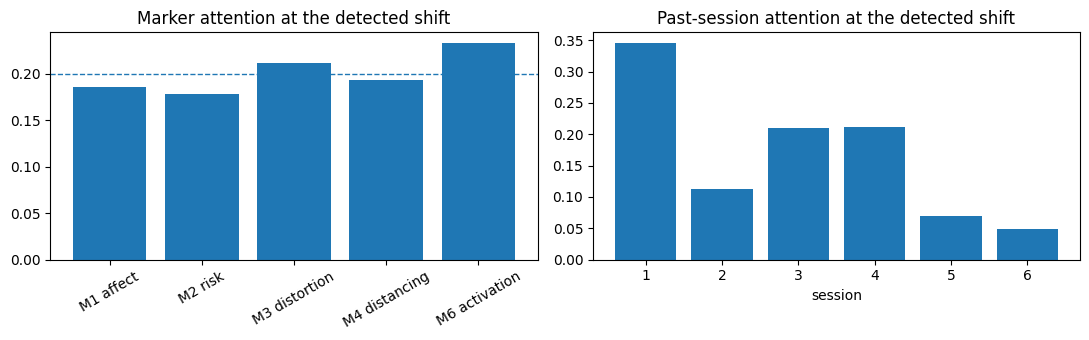

In [29]:
import matplotlib.pyplot as plt

marker_names = ["M1 affect", "M2 risk", "M3 distortion", "M4 distancing", "M6 activation"]

def detected_index(model, x, threshold=0.5):
    model.eval()
    with torch.no_grad():
        probs = torch.sigmoid(model(x)).squeeze(0).numpy()   # this forward pass also stores the attention weights
    hits = np.where(probs >= threshold)[0]
    return (hits[0] if len(hits) > 0 else len(probs) - 1), probs

pid = test_pids[0]
x = test_seqs[test_pids.index(pid)].unsqueeze(0)
t, probs = detected_index(catn, x)

marker_attn = catn.last_construct_w[0, t].mean(dim=0).numpy()    # attention each marker receives
session_attn = catn.last_session_w[0, t, : t + 1].numpy()        # attention on sessions 1..t+1
true_shift = test_df.loc[test_df["patient_id"] == pid, "true_shift_session"].iloc[0]

print(f"{pid}: true shift = session {true_shift}, CATN detected = session {t + 1}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].bar(marker_names, marker_attn)
ax[0].axhline(0.2, linestyle="--", linewidth=1)    # 0.2 = equal attention to all 5 markers
ax[0].set_title("Marker attention at the detected shift")
ax[0].tick_params(axis="x", rotation=30)
ax[1].bar(range(1, t + 2), session_attn)
ax[1].set_title("Past-session attention at the detected shift")
ax[1].set_xlabel("session")
plt.tight_layout()
plt.show()

### Checking the Attention Weights Against Occlusion

**The idea:** for each marker, replace its values with the training average
and see how much the shift probability drops. A big drop means the model
really depended on that marker. This is a direct test, so we can compare
it with the attention weights.

**What to expect in this data:** M2 is zero for every synthetic session, so
occluding it changes nothing and its occlusion drop is exactly 0. If its
attention weight is still around 0.2, attention alone overstates its role.
M1, M4 and M6 carry the real signal, so they should show the biggest drops.

**Rank agreement:** for each patient, the Spearman correlation between the
attention ranking and the occlusion ranking of the five markers, averaged
over patients. Near 1 means the two agree, near 0 means attention is not
a reliable explanation.

**Honest reporting:** whatever the numbers show, report them. Attention
weights are known to be an imperfect explanation (Jain and Wallace, 2019,
"Attention is not Explanation"), so a partial agreement is a normal result.

In [30]:
from scipy.stats import spearmanr

def occlusion_importance(model, x, t):
    # drop in P(shifted) at session t when one marker is replaced by its training average (0 in z-space)
    model.eval()
    with torch.no_grad():
        base = torch.sigmoid(model(x)).squeeze(0)[t].item()
        drops = []
        for j in range(x.shape[-1]):
            x_occ = x.clone()
            x_occ[0, :, j] = 0.0
            drops.append(base - torch.sigmoid(model(x_occ)).squeeze(0)[t].item())
    return np.array(drops)

attn_all, occ_all = [], []
for pid in test_pids:
    x = test_seqs[test_pids.index(pid)].unsqueeze(0)
    t, _ = detected_index(catn, x)
    attn_all.append(catn.last_construct_w[0, t].mean(dim=0).numpy())   # read before the occlusion calls overwrite it
    occ_all.append(occlusion_importance(catn, x, t))

attn_all, occ_all = np.array(attn_all), np.array(occ_all)

summary = pd.DataFrame({
    "marker": marker_names,
    "mean attention": attn_all.mean(axis=0).round(3),
    "mean occlusion drop": occ_all.mean(axis=0).round(3),
})
print(summary.to_string(index=False))

rhos = [spearmanr(a, o)[0] for a, o in zip(attn_all, occ_all)]
print("Mean per-patient rank agreement (attention vs occlusion):", round(np.nanmean(rhos), 2))

       marker  mean attention  mean occlusion drop
    M1 affect           0.203                0.307
      M2 risk           0.195                0.000
M3 distortion           0.209                0.070
M4 distancing           0.203                0.026
M6 activation           0.191                0.105
Mean per-patient rank agreement (attention vs occlusion): -0.19


### Occlusion Attribution: LSTM vs CATN

**What this does:** for each model, replace one marker at a time with its
training average and measure how much the shift probability drops at the
detected shift session, averaged over the 50 test patients.

**Why occlusion for both:** it is a model-agnostic test, so the LSTM and CATN
get the same explanation method and the comparison is fair.

**What to look for:** if both models rank the markers similarly (M1 first),
the explanation comes from the data and not from CATN's architecture. That would
mean CATN's attention weights add nothing beyond what occlusion already
gives for any model.

In [31]:
def mean_occlusion(m, seqs, pids):
    drops = []
    for pid in pids:
        x = seqs[pids.index(pid)].unsqueeze(0)
        t, _ = detected_index(m, x)
        drops.append(occlusion_importance(m, x, t))
    return np.array(drops).mean(axis=0)

compare = pd.DataFrame({
    "marker": marker_names,
    "LSTM occlusion drop": mean_occlusion(model, test_seqs, test_pids).round(3),
    "CATN occlusion drop": mean_occlusion(catn, test_seqs, test_pids).round(3),
})
print(compare.to_string(index=False))

       marker  LSTM occlusion drop  CATN occlusion drop
    M1 affect                0.173                0.307
      M2 risk                0.000                0.000
M3 distortion                0.036                0.070
M4 distancing               -0.083                0.026
M6 activation                0.019                0.105
